# Task 2: Customer Segmentation Analysis

## 1. Objective
Apply clustering algorithms to segment an e-commerce company's customer base into distinct groups based on purchasing behaviour, enabling targeted marketing strategies.

## 2. Problem Statement
Customers have different purchasing patterns, order frequencies, and spending levels. Understanding these differences helps businesses design effective marketing campaigns, improve customer retention, and build stronger customer relationships. This project uses RFM analysis and K-Means clustering to identify meaningful customer segments.

## 3. Dataset Overview
The project uses an online retail transaction dataset containing customer IDs, invoice numbers, invoice dates, quantities, unit prices, and purchase amounts. After data cleaning and filtering, the purchase dataset contains 391,150 records and 10 columns. The RFM analysis includes 4,334 unique customers.

## 4. Key Features
- **Recency:** Number of days since a customer's most recent purchase.
- **Frequency:** Number of distinct invoices associated with a customer.
- **Monetary:** Total purchase amount spent by a customer.
- **Cluster:** Customer segment assigned by the K-Means algorithm.

## 5. Tools and Technologies
- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- StandardScaler
- K-Means Clustering

## 6. Project Methodology
1. Load and inspect the dataset.
2. Handle missing values, duplicates, invalid dates, and invalid purchase records.
3. Perform exploratory data analysis (EDA) and descriptive statistics.
4. Calculate customer-level RFM features.
5. Standardize RFM features using StandardScaler.
6. Apply the Elbow Method to select a suitable number of clusters.
7. Train the K-Means clustering model.
8. Visualize customer segments using scatter plots.
9. Profile clusters and compare customer counts and average RFM values.
10. Interpret customer segments and recommend targeted marketing strategies.

## 7. Expected Outcome
Develop customer segments based on purchasing behaviour, visualize differences between groups, and generate actionable insights to support personalized marketing and customer retention.

## 8. Conclusion
This project demonstrates how exploratory data analysis, RFM feature engineering, and K-Means clustering can be used to understand customer purchasing behaviour and support data-driven marketing decisions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv("online_retail_clean.csv")

In [9]:
display(df.head(8))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom,15.30
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850,United Kingdom,25.50
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 391150 entries, 0 to 391149
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    391150 non-null  int64  
 1   StockCode    391150 non-null  str    
 2   Description  391150 non-null  str    
 3   Quantity     391150 non-null  int64  
 4   InvoiceDate  391150 non-null  str    
 5   UnitPrice    391150 non-null  float64
 6   CustomerID   391150 non-null  int64  
 7   Country      391150 non-null  str    
 8   Revenue      391150 non-null  float64
dtypes: float64(2), int64(3), str(4)
memory usage: 50.7 MB


In [12]:
# Display all column names
# Purpose: Understand which features are available in the dataset

print("Column names in the dataset:")
print(df.columns.tolist())

Column names in the dataset:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']


In [13]:
#  Check missing values in each column
# Purpose: Identify columns that may require data cleaning

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64


In [14]:
#  Identify duplicate rows
# Purpose: Check whether the dataset contains repeated records
# Note: We will not remove duplicates until we inspect the results

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [15]:
#  Generate descriptive statistics
# Purpose: Understand the distribution and summary of the dataset

display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,391150.0,NaN,NaN,NaN,560592.908268,13087.235691,536365.0,549235.0,561875.0,572062.0,581587.0
StockCode,391150,3659,85123A,2023,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,391150,3871,WHITE HANGING HEART T-LIGHT HOLDER,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,391150.0,NaN,NaN,NaN,13.1453,180.807831,1.0,2.0,6.0,12.0,80995.0
InvoiceDate,391150,17166,2011-11-14 15:27:00,541,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,391150.0,NaN,NaN,NaN,2.874372,4.284738,0.04,1.25,1.95,3.75,649.5
CustomerID,391150.0,NaN,NaN,NaN,15295.171456,1710.339033,12346.0,13969.0,15159.0,16794.0,18287.0
Country,391150,37,United Kingdom,348872,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,391150.0,NaN,NaN,NaN,22.337281,310.932442,0.06,4.95,11.9,19.8,168469.6


In [16]:
# Verify required columns for customer segmentation
# Purpose: Confirm that the dataset supports RFM feature calculation

required_columns = [
    "CustomerID",
    "InvoiceDate",
    "InvoiceNo",
    "Quantity",
    "UnitPrice"
]

print("Checking required columns:")

for column in required_columns:
    if column in df.columns:
        print(f"{column}: Available")
    else:
        print(f"{column}: Missing")

Checking required columns:
CustomerID: Available
InvoiceDate: Available
InvoiceNo: Available
Quantity: Available
UnitPrice: Available


In [17]:
# Check dataset dimensions
# Purpose: Determine the number of records and columns

rows, columns = df.shape

print("Total records:", rows)
print("Total columns:", columns)

Total records: 391150
Total columns: 9


In [18]:
#  Inspect invalid or non-positive transaction values
# Purpose: Identify quantities and prices that require investigation
# Note: These records are checked, not automatically deleted

print("Non-positive quantities:", (df["Quantity"] <= 0).sum())
print("Non-positive prices:", (df["UnitPrice"] <= 0).sum())

Non-positive quantities: 0
Non-positive prices: 0


In [19]:
# Create a copy of the original dataset
# Purpose: Preserve the original data in case we need it later

df_clean = df.copy()

print("Working copy created successfully.")
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Working copy created successfully.
Original dataset shape: (391150, 9)
Working dataset shape: (391150, 9)


In [20]:
# Remove exact duplicate rows
# Purpose: Prevent repeated records from affecting our analysis

duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates()

duplicates_after = df_clean.duplicated().sum()

print("Duplicates before cleaning:", duplicates_before)
print("Duplicates after cleaning:", duplicates_after)
print("Dataset shape after removing duplicates:", df_clean.shape)

Duplicates before cleaning: 0
Duplicates after cleaning: 0
Dataset shape after removing duplicates: (391150, 9)


In [21]:
#  Check and remove records with missing customer IDs
# Purpose: Keep transactions that can be linked to a known customer

print("Missing CustomerID values before cleaning:",
      df_clean["CustomerID"].isnull().sum())

df_clean = df_clean.dropna(subset=["CustomerID"])

print("Missing CustomerID values after cleaning:",
      df_clean["CustomerID"].isnull().sum())
print("Dataset shape:", df_clean.shape)

Missing CustomerID values before cleaning: 0
Missing CustomerID values after cleaning: 0
Dataset shape: (391150, 9)


In [22]:
#  Convert InvoiceDate to datetime format
# Purpose: Enable date calculations for Recency analysis

df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

print("Invalid or missing invoice dates:",
      df_clean["InvoiceDate"].isnull().sum())

Invalid or missing invoice dates: 0


In [23]:
#  Remove records without a valid invoice date
# Purpose: Ensure every retained transaction has a usable purchase date

df_clean = df_clean.dropna(subset=["InvoiceDate"])

print("Dataset shape after date validation:", df_clean.shape)

Dataset shape after date validation: (391150, 9)


In [24]:
# Step 3.5: Count transactions with non-positive quantities or prices
# Purpose: Identify records that may represent cancellations or invalid values

print("Non-positive quantities:",
      (df_clean["Quantity"] <= 0).sum())

print("Non-positive prices:",
      (df_clean["UnitPrice"] <= 0).sum())

Non-positive quantities: 0
Non-positive prices: 0


In [25]:
# Create a dataset containing positive purchase lines
# Purpose: Calculate customer spending from valid positive quantities and prices
# Note: This is an analytical filter, not a replacement for the full cleaned dataset

df_purchases = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

print("Purchase records before filtering:", len(df_clean))
print("Positive purchase records:", len(df_purchases))
print("Purchase dataset shape:", df_purchases.shape)

Purchase records before filtering: 391150
Positive purchase records: 391150
Purchase dataset shape: (391150, 9)


In [26]:
#  Calculate the value of each purchase line
# Purpose: Use quantity multiplied by unit price to measure transaction value

df_purchases["TotalAmount"] = (
    df_purchases["Quantity"] *
    df_purchases["UnitPrice"]
)

display(
    df_purchases[
        ["CustomerID", "InvoiceNo", "Quantity",
         "UnitPrice", "TotalAmount"]
    ].head()
)

,CustomerID,InvoiceNo,Quantity,UnitPrice,TotalAmount
0,17850,536365,6,2.55,15.30
1,17850,536365,6,3.39,20.34
2,17850,536365,8,2.75,22.00
3,17850,536365,6,3.39,20.34
4,17850,536365,6,3.39,20.34


In [27]:
# Verify the data after cleaning
# Purpose: Confirm the dataset is ready for exploratory analysis

print("Final purchase dataset shape:", df_purchases.shape)
print("Remaining missing values:")
print(df_purchases.isnull().sum())

print("Remaining duplicate rows:",
      df_purchases.duplicated().sum())

display(df_purchases.head())

Final purchase dataset shape: (391150, 10)
Remaining missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
TotalAmount    0
dtype: int64
Remaining duplicate rows: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,20.34


In [28]:
#  Display the dataset structure
# Purpose: Confirm the columns and data types before analysis

print("Dataset shape:", df_purchases.shape)
print("\nColumn names:")
print(df_purchases.columns.tolist())

print("\nDataset information:")
df_purchases.info()

# Display the first five records
display(df_purchases.head())

Dataset shape: (391150, 10)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'TotalAmount']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 391150 entries, 0 to 391149
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    391150 non-null  int64         
 1   StockCode    391150 non-null  str           
 2   Description  391150 non-null  str           
 3   Quantity     391150 non-null  int64         
 4   InvoiceDate  391150 non-null  datetime64[us]
 5   UnitPrice    391150 non-null  float64       
 6   CustomerID   391150 non-null  int64         
 7   Country      391150 non-null  str           
 8   Revenue      391150 non-null  float64       
 9   TotalAmount  391150 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(3), str(3)
memory usage: 46.6 MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,20.34


In [29]:
#  Calculate descriptive statistics
# Purpose: Understand typical quantities, prices, and purchase amounts

display(
    df_purchases[
        ["Quantity", "UnitPrice", "TotalAmount"]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Quantity,391150.0,13.145300,180.807831,1.00,2.00,6.00,12.00,80995.0
UnitPrice,391150.0,2.874372,4.284738,0.04,1.25,1.95,3.75,649.5
TotalAmount,391150.0,22.337281,310.932442,0.06,4.95,11.90,19.80,168469.6


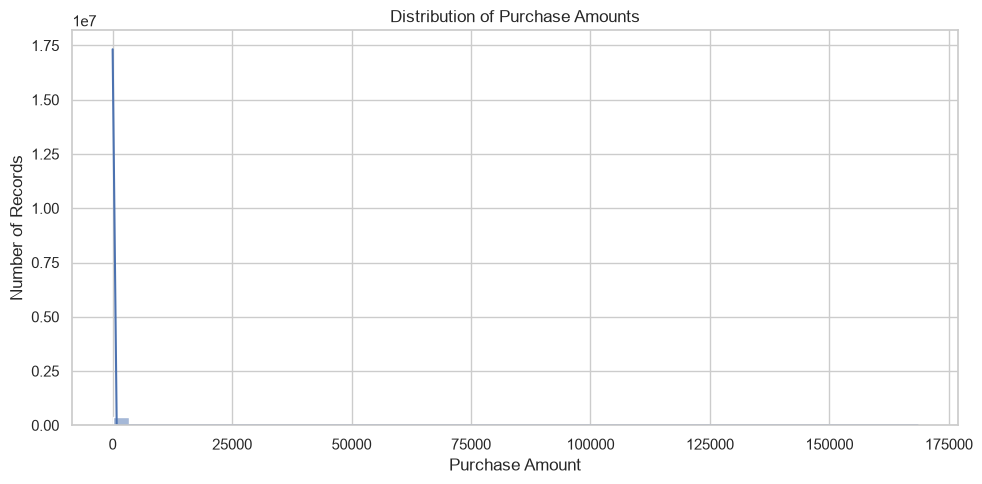

In [30]:
# Step 4.4: Plot the distribution of purchase amounts
# Purpose: See how purchase values are distributed across transaction lines

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_purchases,
    x="TotalAmount",
    bins=50,
    kde=True
)

plt.title("Distribution of Purchase Amounts")
plt.xlabel("Purchase Amount")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

,CustomerID,TotalSpending
0,14646,279138.02
1,18102,259657.30
2,17450,194390.79
3,16446,168472.50
4,14911,136161.83
5,12415,124564.53
6,14156,116560.08
7,17511,91062.38
8,12346,77183.60
9,16029,72708.09


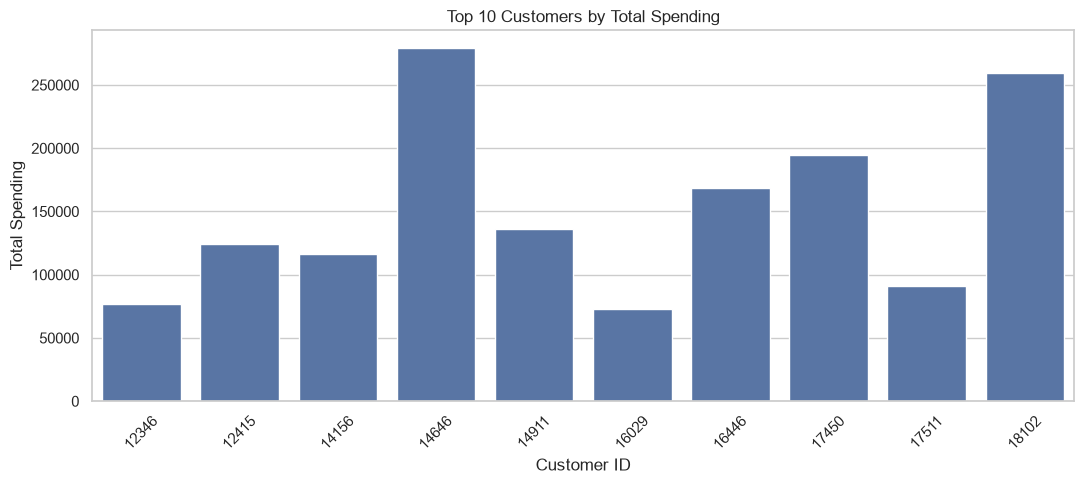

In [31]:
#  Find the top 10 customers by total spending
# Purpose: Identify customers who contributed the most revenue

top_customers = (
    df_purchases.groupby("CustomerID")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_customers.columns = ["CustomerID", "TotalSpending"]

display(top_customers)

# Plot the top 10 customers
plt.figure(figsize=(11, 5))

sns.barplot(
    data=top_customers,
    x="CustomerID",
    y="TotalSpending"
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,InvoiceMonth,TotalAmount
0,2010-12,565199.56
1,2011-01,562682.91
2,2011-02,442293.59
3,2011-03,583143.85
4,2011-04,454440.88


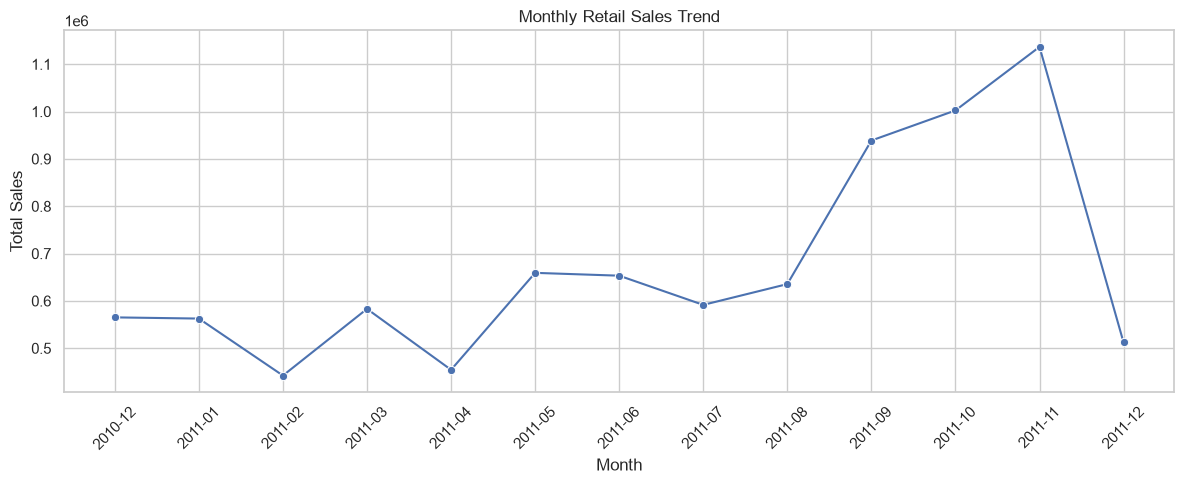

In [33]:
#  Analyze sales by month
# Purpose: Understand how total sales change over time

df_purchases["InvoiceMonth"] = (
    df_purchases["InvoiceDate"].dt.to_period("M").astype(str)
)

monthly_sales = (
    df_purchases.groupby("InvoiceMonth")["TotalAmount"]
    .sum()
    .reset_index()
)

display(monthly_sales.head())

# Plot monthly sales
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="InvoiceMonth",
    y="TotalAmount",
    marker="o"
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 4: Exploratory Data Analysis — Observations

1. **Dataset Overview:** The cleaned purchase dataset contains 391,150 records and 10 columns, including customer IDs, invoice dates, quantities, unit prices, and purchase amounts.

2. **Purchase Distribution:** Purchase amounts are highly right-skewed. Most purchase records have relatively small values, while a few transactions have exceptionally high values. The median purchase amount is 11.90, compared with a mean of 22.34.

3. **Top Customers:** Customer ID 14646 is the highest-spending customer in the analyzed dataset, with total spending of approximately 279,138.02.

4. **Monthly Sales Trend:** Monthly sales fluctuate over time. November 2011 recorded the highest sales at approximately 1.14 million, while February 2011 recorded the lowest sales at approximately 442,293.59.

5. **Conclusion:** The EDA reveals differences in purchase amounts, customer spending, and monthly sales. These findings support using RFM analysis and K-Means clustering to identify distinct customer segments and develop targeted marketing strategies.

In [35]:
# Count unique customers
# Purpose: Identify how many individual customers are included in the analysis

print("Total unique customers:", df_purchases["CustomerID"].nunique())

Total unique customers: 4334


In [36]:
# Set the reference date for RFM analysis
# Purpose: Calculate how recently each customer made a purchase
# We use one day after the latest invoice date as the reference date

reference_date = df_purchases["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Latest invoice date:", df_purchases["InvoiceDate"].max())
print("Reference date for RFM:", reference_date)

Latest invoice date: 2011-12-09 12:50:00
Reference date for RFM: 2011-12-10 12:50:00


In [37]:
# Calculate RFM values for each customer
# Purpose: Summarize customer purchase behaviour

rfm = df_purchases.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (reference_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
).reset_index()

# Display the first five customer records
display(rfm.head())

# Check the number of customers and RFM columns
print("RFM dataset shape:", rfm.shape)

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1437.24
3,12349,19,1,1457.55
4,12350,310,1,294.40


RFM dataset shape: (4334, 4)


In [38]:
# Step 5.3: Review descriptive statistics of RFM values
# Purpose: Understand the range and distribution of customer behaviour

display(rfm[["Recency", "Frequency", "Monetary"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
Recency,4334.0,92.703046,100.177047,1.00,18.00,51.000,143.0000,374.00
Frequency,4334.0,4.245962,7.634989,1.00,1.00,2.000,5.0000,206.00
Monetary,4334.0,2015.973152,8903.673825,3.75,304.24,662.565,1631.6225,279138.02


In [39]:
# Validate the RFM dataset
# Purpose: Ensure customer-level features are ready for clustering

print("Missing values:")
print(rfm[["Recency", "Frequency", "Monetary"]].isnull().sum())

print("\nRecency values less than zero:", (rfm["Recency"] < 0).sum())
print("Frequency values less than or equal to zero:", (rfm["Frequency"] <= 0).sum())
print("Monetary values less than or equal to zero:", (rfm["Monetary"] <= 0).sum())

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Recency values less than zero: 0
Frequency values less than or equal to zero: 0
Monetary values less than or equal to zero: 0


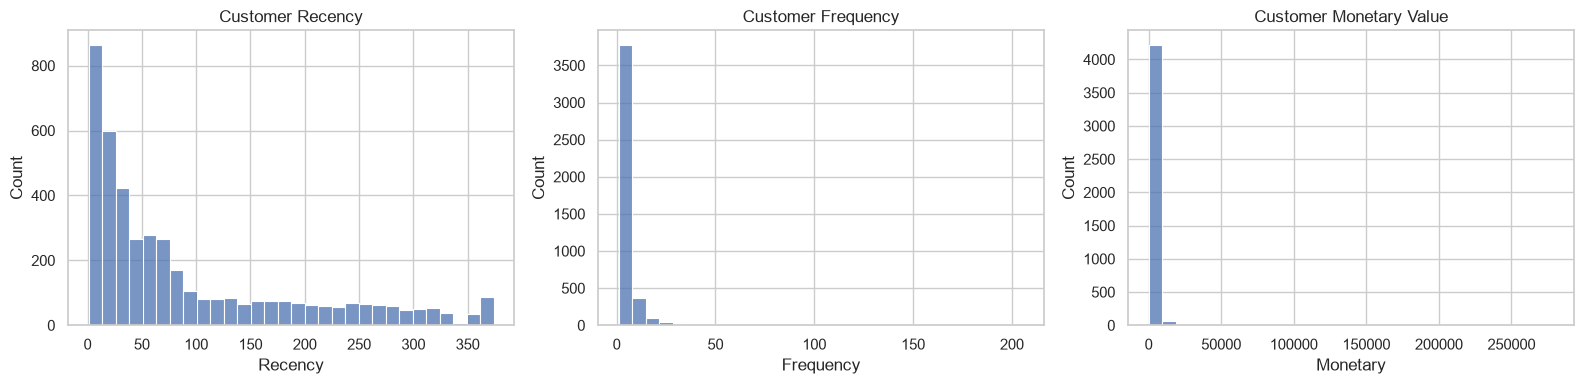

In [40]:
# Plot the distribution of RFM features
# Purpose: Understand differences between customers before clustering

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(data=rfm, x="Recency", bins=30, ax=axes[0])
axes[0].set_title("Customer Recency")

sns.histplot(data=rfm, x="Frequency", bins=30, ax=axes[1])
axes[1].set_title("Customer Frequency")

sns.histplot(data=rfm, x="Monetary", bins=30, ax=axes[2])
axes[2].set_title("Customer Monetary Value")

plt.tight_layout()
plt.show()

In [41]:
# Import StandardScaler
# Purpose: Standardize RFM features so they are on comparable scales

from sklearn.preprocessing import StandardScaler

# Select the features used for customer segmentation
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]

# Create the scaler and transform the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

print("Original RFM shape:", rfm_features.shape)
print("Scaled RFM shape:", rfm_scaled.shape)

Original RFM shape: (4334, 3)
Scaled RFM shape: (4334, 3)


In [42]:
# Convert scaled values into a DataFrame
# Purpose: Make standardized values easier to inspect

rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency_Scaled", "Frequency_Scaled", "Monetary_Scaled"],
    index=rfm.index
)

display(rfm_scaled_df.head())

# Check the means and standard deviations after scaling
display(rfm_scaled_df.describe().T)

,Recency_Scaled,Frequency_Scaled,Monetary_Scaled
0,2.329115,-0.425192,8.443290
1,-0.905532,0.360754,0.257679
2,-0.176738,-0.032219,-0.065007
3,-0.735813,-0.425192,-0.062726
4,2.169379,-0.425192,-0.193378


,count,mean,std,min,25%,50%,75%,max
Recency_Scaled,4334.0,-5.697130e-17,1.000115,-0.915515,-0.745796,-0.416341,0.502139,2.808322
Frequency_Scaled,4334.0,-1.639462e-18,1.000115,-0.425192,-0.425192,-0.294201,0.098772,26.427978
Monetary_Scaled,4334.0,-1.065650e-17,1.000115,-0.226025,-0.192272,-0.152023,-0.043173,31.128052


In [43]:
# Import K-Means
# Purpose: Test different numbers of clusters

from sklearn.cluster import KMeans

# Calculate inertia for cluster counts from 1 to 10
inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(rfm_scaled)
    inertia_values.append(kmeans.inertia_)

print("Inertia values:", inertia_values)

Inertia values: [13002.000000000007, 9008.051261075878, 5434.393135664872, 4099.9285662516495, 3094.027479073702, 2456.225347571394, 2014.9443875881207, 1701.7611714917346, 1439.6022338999257, 1266.7889878779517]


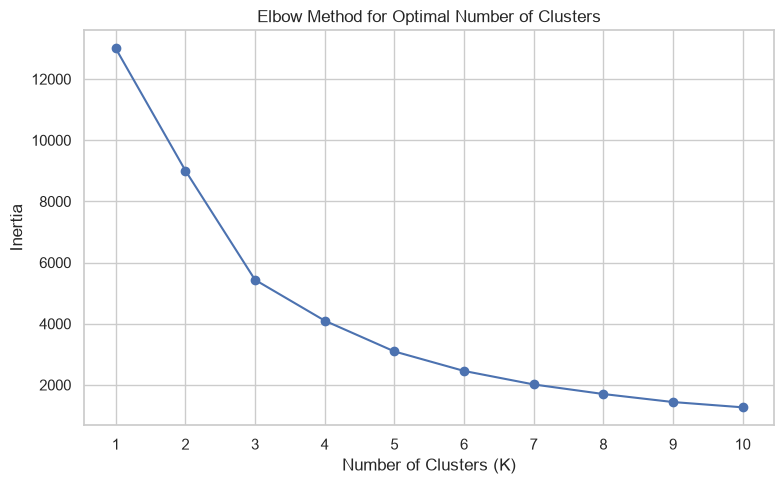

In [44]:
# Plot the Elbow Method graph
# Purpose: Identify a suitable number of customer clusters

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.tight_layout()
plt.show()

In [45]:
# Train the K-Means clustering model
# Purpose: Group customers based on their Recency, Frequency, and Monetary values

from sklearn.cluster import KMeans

# Choose the number of clusters based on the Elbow Method
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Assign a cluster to each customer
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("K-Means clustering completed successfully.")
print("Number of clusters:", optimal_k)

K-Means clustering completed successfully.
Number of clusters: 4


In [46]:
# Count customers in each cluster
# Purpose: Understand how customers are distributed among the groups

cluster_counts = rfm["Cluster"].value_counts().sort_index()

display(cluster_counts.to_frame(name="CustomerCount"))

print("Total customers segmented:", rfm["CustomerID"].nunique())

,CustomerCount
Cluster,
0,3045
1,1066
2,13
3,210


Total customers segmented: 4334


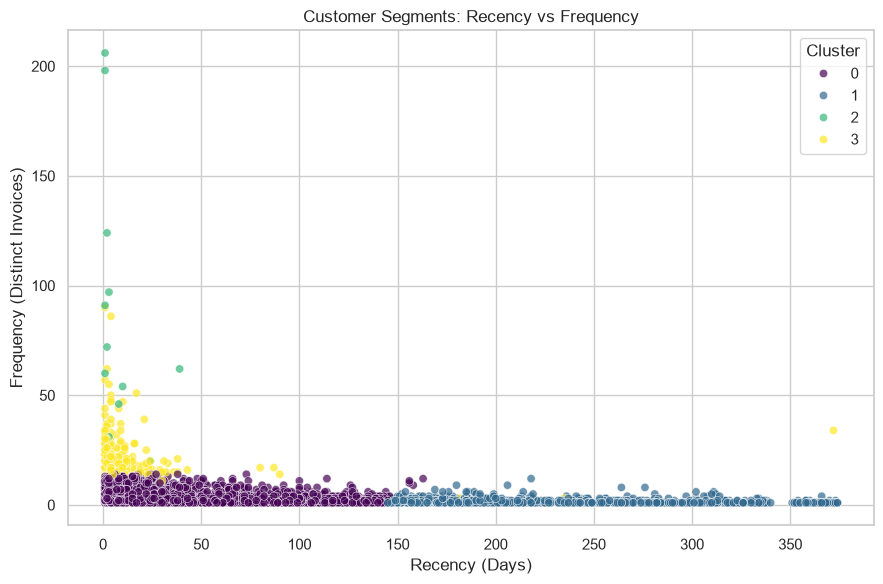

In [47]:
# Visualize clusters using Recency and Frequency
# Purpose: Compare customer groups based on purchase recency and frequency

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette="viridis",
    alpha=0.7
)

plt.title("Customer Segments: Recency vs Frequency")
plt.xlabel("Recency (Days)")
plt.ylabel("Frequency (Distinct Invoices)")
plt.tight_layout()
plt.show()

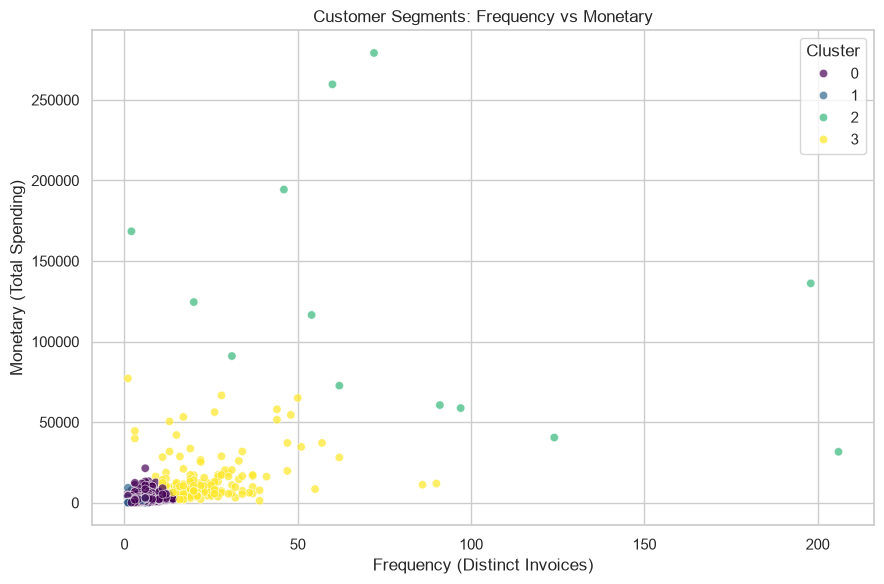

In [48]:
#  Visualize clusters using Frequency and Monetary value
# Purpose: Compare purchase frequency with total customer spending

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    alpha=0.7
)

plt.title("Customer Segments: Frequency vs Monetary")
plt.xlabel("Frequency (Distinct Invoices)")
plt.ylabel("Monetary (Total Spending)")
plt.tight_layout()
plt.show()

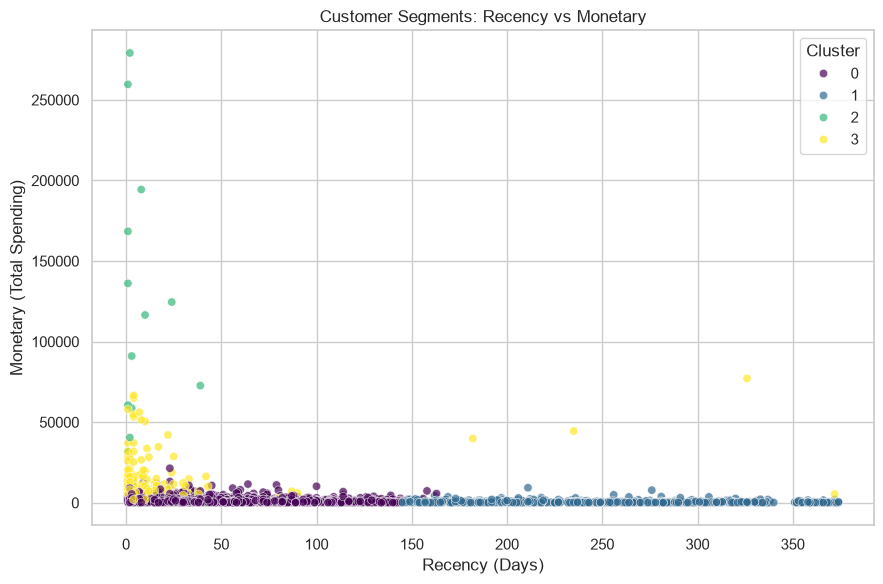

In [49]:
#  Visualize clusters using Recency and Monetary value
# Purpose: Compare how recently customers purchased with how much they spent

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    alpha=0.7
)

plt.title("Customer Segments: Recency vs Monetary")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary (Total Spending)")
plt.tight_layout()
plt.show()

In [50]:
# Profile each customer cluster
# Purpose: Compare customer behaviour using average RFM values

cluster_profile = rfm.groupby("Cluster").agg(
    CustomerCount=("CustomerID", "count"),
    AverageRecency=("Recency", "mean"),
    AverageFrequency=("Frequency", "mean"),
    AverageMonetary=("Monetary", "mean")
).round(2)

display(cluster_profile)

,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary
Cluster,,,,
0,3045,43.84,3.64,1322.51
1,1066,248.54,1.54,474.12
2,13,7.38,81.77,125712.09
3,210,15.40,21.97,12240.55


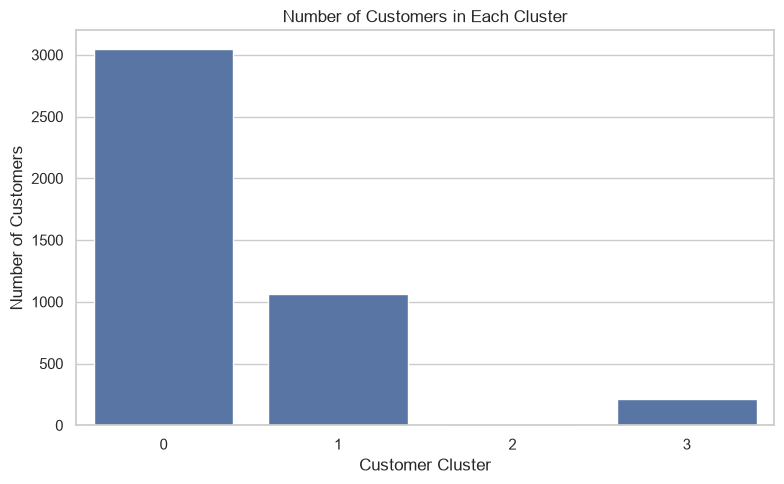

In [51]:
#  Visualize the number of customers in each cluster
# Purpose: Compare the sizes of the customer segments

plt.figure(figsize=(8, 5))

sns.barplot(
    data=cluster_profile.reset_index(),
    x="Cluster",
    y="CustomerCount"
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

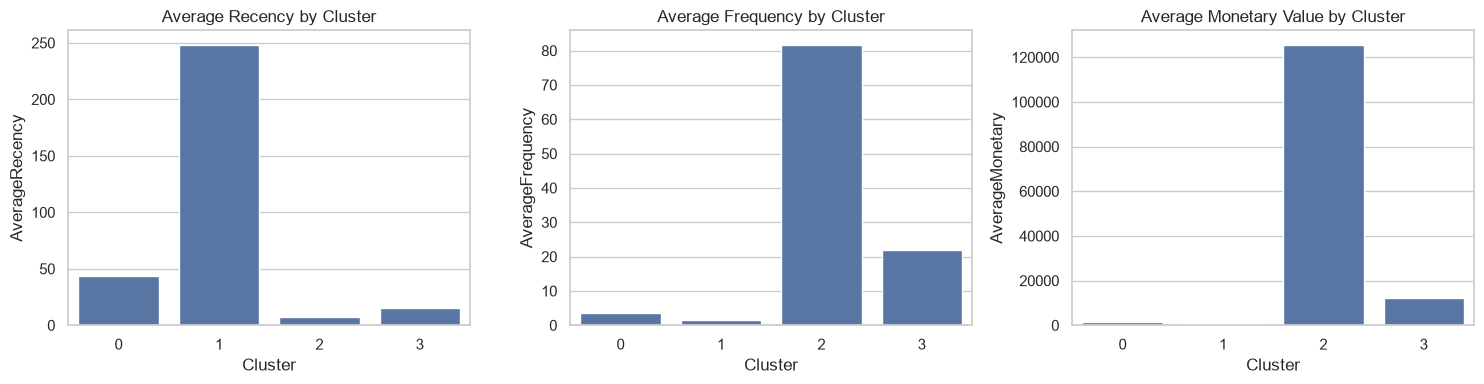

In [52]:
#  Compare average RFM values across clusters
# Purpose: Identify differences in customer purchasing behaviour

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(
    data=cluster_profile.reset_index(),
    x="Cluster",
    y="AverageRecency",
    ax=axes[0]
)
axes[0].set_title("Average Recency by Cluster")

sns.barplot(
    data=cluster_profile.reset_index(),
    x="Cluster",
    y="AverageFrequency",
    ax=axes[1]
)
axes[1].set_title("Average Frequency by Cluster")

sns.barplot(
    data=cluster_profile.reset_index(),
    x="Cluster",
    y="AverageMonetary",
    ax=axes[2]
)
axes[2].set_title("Average Monetary Value by Cluster")

plt.tight_layout()
plt.show()

In [53]:
#  Export customer segmentation results
# Purpose: Save the final customer-level results for reporting

rfm.to_csv("customer_segmentation_results.csv", index=False)

print("Customer segmentation results saved successfully.")

Customer segmentation results saved successfully.


# Customer Segment Interpretation and Marketing Recommendations

## Cluster 0 — Regular Customers
These 3,045 customers have moderate recency, purchase frequency, and spending. They represent the largest customer group.

**Marketing Recommendation:** Encourage repeat purchases through personalized product recommendations, loyalty points, and occasional promotional offers.

##  Cluster 1 — Inactive or At-Risk Customers
These 1,066 customers have the highest average recency (248.54 days), the lowest purchase frequency, and the lowest average spending. They may be inactive or at risk of not returning.

**Marketing Recommendation:** Use re-engagement email campaigns, limited-time discounts, and personalized reminders to encourage them to purchase again.

## Cluster 2 — Highest-Value Customers
These 13 customers have the lowest average recency, highest purchase frequency, and highest average spending. They appear to be exceptionally valuable customers.

**Marketing Recommendation:** Provide VIP benefits, exclusive offers, personalized service, and early access to new products. Review this small group separately because a few unusually large purchases may influence the averages.

## Cluster 3 — High-Value, Frequent Customers
These 210 customers have relatively recent purchases, high purchase frequency, and high average spending compared with the larger customer groups.

**Marketing Recommendation:** Strengthen loyalty through reward programs, premium product recommendations, exclusive bundles, and targeted cross-selling.

## Overall Business Insights
The K-Means model identified four customer groups with different purchasing patterns. Cluster 0 represents the largest group, Cluster 1 contains customers who may need re-engagement, Cluster 2 contains a small group of exceptionally high-value customers, and Cluster 3 represents frequent, high-spending customers.

These segments can help the business design targeted marketing campaigns, improve customer retention, and allocate promotional resources more effectively.

**Note:** Cluster numbers are algorithm-generated labels, not rankings. Customer categories and recommendations are interpretations of the observed RFM averages.